      iteration      loss  learning_rate  grad_norm  step_ok  gpu_memory_gb
9966       9903  4.184799       0.000296   0.522895     True      14.611998
9967       9904  4.118902       0.000296   0.554325     True      14.611998
9968       9905  4.136160       0.000296   0.546853     True      14.611998
9969       9906  4.038075       0.000296   0.551254     True      14.611998
9970       9907  4.123230       0.000296   0.541683     True      14.611998


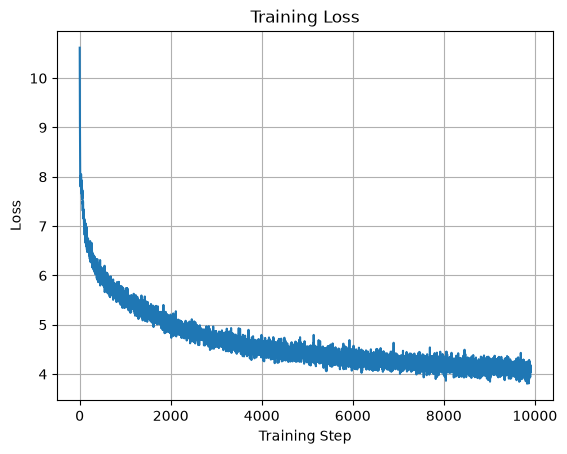

In [64]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("logs/training_l.csv")

print(df.tail())

plt.plot(df["iteration"], df["loss"])
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

In [69]:
%%writefile inference.py
# python module
import math
import os
import random
from contextlib import contextmanager
import time
from pathlib import Path
import csv

# torch and numpy imports
import numpy as np
import torch
import torch.distributed as dist
import torch.multiprocessing as mp
import torch.nn.functional as F
from torch.utils.data import DataLoader, DistributedSampler
from tokenizers import Tokenizer

# megatron-core imports
from megatron.core import parallel_state
from megatron.core.datasets.blended_megatron_dataset_builder import (
    BlendedMegatronDatasetBuilder
)
from megatron.core.datasets.gpt_dataset import GPTDataset, GPTDatasetConfig
from megatron.core.distributed import finalize_model_grads
from megatron.core.pipeline_parallel.schedules import get_forward_backward_func
from megatron.core.tensor_parallel.random import model_parallel_cuda_manual_seed

# repo modules
from model_block import build_llama_model
from distributed_helper import wrap_model_for_distributed_training, build_optimizer
from simple_tokenizer import SimpleTokenizer

N_MODEL = {
	'd_model' : 384,
	'd_ff' : 1024,
	'num_layers' : 6,
 	'num_heads' : 8,
}

S_MODEL = {
	'd_model' : 768,
	'd_ff' : 3072,
	'num_layers' : 12,
	'num_heads' : 12  
}
M_MODEL = {
	'd_model' : 1024,
	'd_ff' : 4096,
	'num_layers' : 24,
	'num_heads' : 16  
}
L_MODEL = {
	'd_model' : 1280,
	'd_ff' : 5120,
	'num_layers' : 36,
	'num_heads' : 20  
}
XL_MODEL = {
	'd_model' : 2560,
	'd_ff' : 10240,
	'num_layers' : 32,
	'num_heads' : 32  
}

TOKENIZER_PATH = "../tokenizer_02/fineweb_bpe_32k.json"

CONTEXT_LENGTH = 1024
VOCAB_SIZE = 32000
MODEL_SIZE = "l"
CHECKPOINT_DIR = f"checkpoints_{MODEL_SIZE}/step_00010000"

MAX_NEW_TOKENS = 128

# Sampling temperature
TEMPERATURE = 0.8

# Parallelism
TP_SIZE = 2
PP_SIZE = 1
WORLD_SIZE = 2

assert WORLD_SIZE % (TP_SIZE * PP_SIZE) == 0
DP_SIZE = WORLD_SIZE // (TP_SIZE * PP_SIZE)

SEED = 1337

MASTER_ADDR = "localhost"
MASTER_PORT = "29500"

MODEL_SIZES = {
    "n": N_MODEL,
    "s": S_MODEL,
    "m": M_MODEL,
    "l": L_MODEL,
    "xl": XL_MODEL,
}


def setup(rank, world_size):
    os.environ["MASTER_ADDR"] = MASTER_ADDR
    os.environ["MASTER_PORT"] = MASTER_PORT

    torch.cuda.set_device(rank)

    dist.init_process_group(
        backend="nccl",
        rank=rank,
        world_size=world_size,
        device_id=torch.device(f"cuda:{rank}"),
    )

    parallel_state.initialize_model_parallel(
        tensor_model_parallel_size=TP_SIZE,
        pipeline_model_parallel_size=PP_SIZE,
    )


def load_checkpoint(model, rank):
    tp_rank = parallel_state.get_tensor_model_parallel_rank()

    checkpoint_path = f"{CHECKPOINT_DIR}/rank_{tp_rank}.pt"
    checkpoint = torch.load(checkpoint_path, map_location=f"cuda:{rank}", weights_only=True,)

    model.load_state_dict(checkpoint["model"], strict=True,)
    if rank == 0:
        print("Checkpoint loaded successfully", flush=True)


def cleanup():
    if parallel_state.is_initialized():
        parallel_state.destroy_model_parallel()

    if dist.is_initialized():
        dist.destroy_process_group()


@torch.no_grad()
def test_generation(model, tokenizer, rank):
    model.eval()

    tp_group = parallel_state.get_tensor_model_parallel_group()
    tp_size = parallel_state.get_tensor_model_parallel_world_size()
    tp_src_rank = parallel_state.get_tensor_model_parallel_src_rank()

    device = torch.device(f"cuda:{rank}")

    if TEMPERATURE <= 0:
        raise ValueError("TEMPERATURE must be greater than zero.")

    eos_id = getattr(tokenizer, "eod", None)
    if eos_id is None:
        eos_id = tokenizer._tok.token_to_id("<|endoftext|>")

    prompts = [
        "There is a",
        "Once upon a time",
    ]

    for prompt in prompts:

        prompt_ids = tokenizer._tok.encode(prompt, add_special_tokens=False,).ids

        if not prompt_ids:
            raise ValueError("Prompt produced zero tokens.")

        generated = torch.tensor([prompt_ids], dtype=torch.long, device=device,)

        max_new = min(MAX_NEW_TOKENS, CONTEXT_LENGTH - len(prompt_ids),)

        if max_new <= 0:
            raise ValueError("Prompt length exceeds the context window.")

        for _ in range(max_new):

            seq_len = generated.size(1)

            position_ids = torch.arange(seq_len, device=device, ).unsqueeze(0)

            attention_mask = torch.triu(
                torch.ones((1, 1, seq_len, seq_len),device=device,dtype=torch.bool),
                diagonal=1,)

            logits = model(
                input_ids=generated,
                position_ids=position_ids,
                attention_mask=attention_mask,
                labels=None)[:, -1, :]

            if logits.size(-1) == VOCAB_SIZE:

                # Full vocabulary is already available.
                full_logits = logits

            elif logits.size(-1) * tp_size == VOCAB_SIZE:

                # Each TP rank holds a contiguous vocabulary shard.
                gathered_logits = [torch.empty_like(logits) for _ in range(tp_size)]
                
                dist.all_gather(gathered_logits, logits.contiguous(), group=tp_group)

                full_logits = torch.cat(gathered_logits, dim=-1)

            else:
                raise ValueError(f"Unexpected vocabulary dimension: {logits.shape}")

            if rank == tp_src_rank:

                probabilities = F.softmax(full_logits.float() / TEMPERATURE, dim=-1)
                next_id = torch.multinomial(probabilities, num_samples=1)

            else:
                next_id = torch.empty((1, 1), dtype=torch.long, device=device)

            dist.broadcast(next_id, src=tp_src_rank, group=tp_group, )
            generated = torch.cat([generated, next_id], dim=1,)

            if eos_id is not None and next_id.item() == eos_id:
                break

        if rank == 0:

            response_ids = generated[0, len(prompt_ids):].tolist()
            print("\n" + "=" * 60)
            print(f"PROMPT: {prompt}")
            print(f"TEMPERATURE: {TEMPERATURE}")
            print(f"GENERATED TOKENS: {len(response_ids)}")
            print(
                f"RESPONSE: "
                f"{tokenizer._tok.decode(response_ids, skip_special_tokens=True)}"
            )
            print("=" * 60, flush=True)


def train(rank, world_size):

    setup(rank, world_size)
    try:
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed(SEED)


        model_parallel_cuda_manual_seed(SEED)

        model = build_llama_model(
            MODEL_SIZES[MODEL_SIZE],
            VOCAB_SIZE,
            TP_SIZE,
            PP_SIZE,
            CONTEXT_LENGTH,
        )

        model.cuda()
        model.eval()

        # Load pretrained model weights.
        load_checkpoint(model, rank)

        total_params = sum(p.numel() for p in model.parameters())

        tp_rank = parallel_state.get_tensor_model_parallel_rank()
        tp_group = parallel_state.get_tensor_model_parallel_group()

        local_params = sum(p.numel() for p in model.parameters())

        unique_local_params = sum(
            p.numel()
            for p in model.parameters()
            if getattr(p, "tensor_model_parallel", False)
            or tp_rank == 0
        )

        total_params = torch.tensor(unique_local_params, device="cuda", dtype=torch.long)

        dist.all_reduce(total_params, op=dist.ReduceOp.SUM, group=tp_group,)

        if rank == 0:
            print("*" * 32)
            print(f"GPU 0 parameters: {local_params:,}")
            print(f"Full model parameters: {total_params.item():,}")
            print(f"Model size: {total_params.item() / 1e6:.2f}M")
            print("*" * 32)
            
        tokenizer = SimpleTokenizer(TOKENIZER_PATH)

        dist.barrier()
        test_generation(model=model, tokenizer=tokenizer, rank=rank)
        dist.barrier()

    finally:
        cleanup()


if __name__ == "__main__":
    mp.spawn(
        train,
        args=(WORLD_SIZE,),
        nprocs=WORLD_SIZE,
        join=True,
    )

Writing inference.py
